# Palmer Penguins: why grouping matters

**Question:** How do body mass and flipper length differ across species, and does the pooled relationship describe each species equally well?

This small exploratory analysis practices missing-value handling, grouped summaries, visualization, and uncertainty. It uses observed public research data, not simulated records. The analysis describes the sample and does not establish causes.

**Plan:** audit the data; summarize body mass by species; compare pooled and within-species correlations; check the sex composition of the sample. No predictive model is needed for this question.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    raise RuntimeError("Run this notebook from the project folder containing data/.")
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 15, "font.size": 10})
COLORS = ["#167D9A", "#E59236", "#7557A5"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()

def save_json(name, obj):
    (OUT / name).write_text(json.dumps(obj, indent=2, allow_nan=False) + "\n", encoding="utf-8")

def verify_source(filename):
    manifest = json.loads((ROOT / "data" / "provenance.json").read_text())
    actual = hashlib.sha256((ROOT / "data" / filename).read_bytes()).hexdigest()
    assert actual == manifest["sha256"], "The raw data changed; review provenance before rerunning."
    return manifest

save_json("environment.json", {"python": platform.python_version(), **{
    p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "scikit-learn", "nbclient", "nbformat"]}})


## 1. Inspect the data before cleaning

The bundled simplified Palmer Penguins dataset has measurements from three species and islands, collected in 2007–2009. Millimeters measure lengths; grams measure mass. Missing sex does not prevent a row from contributing to an analysis of mass and flipper length, so each analysis uses only its required complete fields.

Source: [Horst, Hill & Gorman, palmerpenguins](https://allisonhorst.github.io/palmerpenguins/). Data collected by Kristen Gorman and Palmer Station LTER; CC0. See `data/README.md` for provenance.


In [2]:
verify_source("penguins.csv")
df = pd.read_csv(ROOT / "data/penguins.csv")
assert df.shape == (344, 8)
assert set(df.species) == {"Adelie", "Chinstrap", "Gentoo"}
missing = df.isna().sum().rename("missing_rows").to_frame()
missing["percent"] = 100 * missing.missing_rows / len(df)
display(df.head())
display(missing)
print("Exact duplicate records:", int(df.duplicated().sum()))
missing.to_csv(OUT / "missingness.csv")
morph = df.dropna(subset=["flipper_length_mm", "body_mass_g"]).copy()
sex_data = df.dropna(subset=["sex", "body_mass_g"]).copy()
print(f"Morphology analysis: {len(morph)} of {len(df)} rows")
print(f"Sex comparison: {len(sex_data)} of {len(df)} rows")
assert len(morph) == 342 and len(sex_data) == 333
assert morph.body_mass_g.gt(0).all()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,missing_rows,percent
species,0,0.000000
island,0,0.000000
bill_length_mm,2,0.581395
bill_depth_mm,2,0.581395
flipper_length_mm,2,0.581395
body_mass_g,2,0.581395
sex,11,3.197674
year,0,0.000000


Exact duplicate records: 0
Morphology analysis: 342 of 344 rows
Sex comparison: 333 of 344 rows


## 2. Estimate sample mean mass with uncertainty

Bootstrap resampling draws observations with replacement within each species 2,000 times. The interval below is the 2.5th–97.5th percentile of those sample means. It assumes the sampled records are independent and representative; nesting, year, island, and sampling design can violate that assumption. These are approximate descriptive intervals, not proof about all penguins.


,n,mean_mass_g,median_mass_g,sd_mass_g,bootstrap_low_g,bootstrap_high_g
species,,,,,,
Adelie,151,3700.7,3700.0,458.6,3628.1,3773.4
Chinstrap,68,3733.1,3700.0,384.3,3637.8,3826.5
Gentoo,123,5076.0,5000.0,504.1,4993.3,5160.4


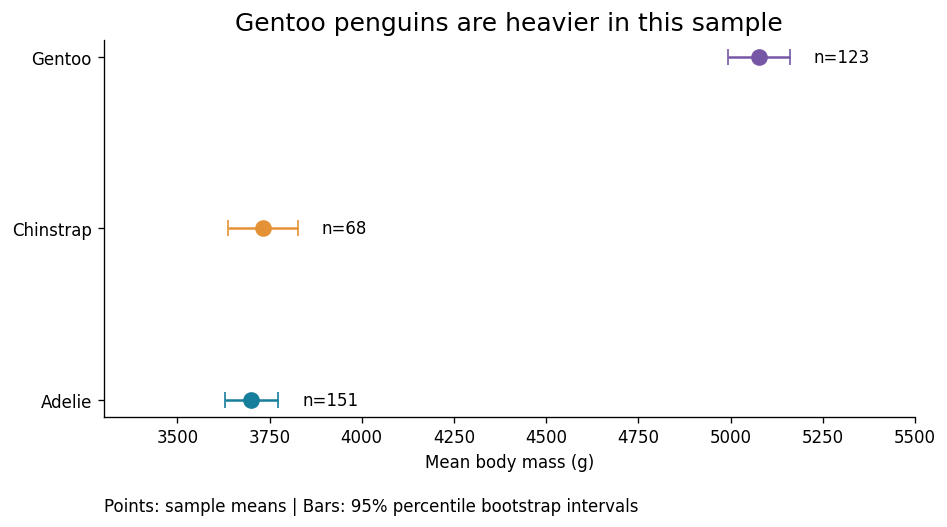

In [3]:
rng = np.random.default_rng(SEED)
rows = []
for species, group in morph.groupby("species", sort=True):
    values = group.body_mass_g.to_numpy()
    means = rng.choice(values, size=(2000, len(values)), replace=True).mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    rows.append({"species": species, "n": len(values), "mean_mass_g": values.mean(),
                 "median_mass_g": np.median(values), "sd_mass_g": values.std(ddof=1),
                 "bootstrap_low_g": lo, "bootstrap_high_g": hi})
summary = pd.DataFrame(rows).set_index("species")
display(summary.round(1))
summary.to_csv(OUT / "species_summary.csv")
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, (species, row) in enumerate(summary.iterrows()):
    ax.errorbar(row.mean_mass_g, i,
                xerr=[[row.mean_mass_g-row.bootstrap_low_g], [row.bootstrap_high_g-row.mean_mass_g]],
                fmt="o", color=COLORS[i], capsize=5, markersize=9)
    ax.annotate(f"n={int(row.n)}", (row.bootstrap_high_g + 65, i), va="center")
ax.set(yticks=range(3), yticklabels=summary.index, xlabel="Mean body mass (g)",
       title="Gentoo penguins are heavier in this sample", xlim=(3300, 5500))
ax.text(0, -0.25, "Points: sample means | Bars: 95% percentile bootstrap intervals", transform=ax.transAxes)
savefig("mass_by_species.png")


## 3. Compare pooled and within-species relationships

Pearson correlation measures the strength of a linear association, from −1 to 1. Combining species can produce a stronger relationship than the relationship within any one species because species differ in both typical mass and flipper length.


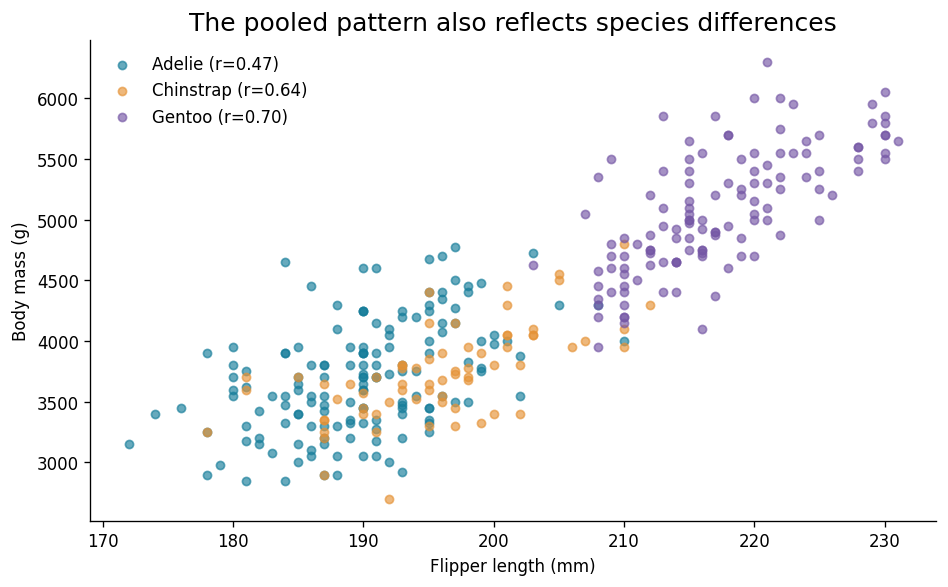

,group,n,pearson_r
0,All species,342,0.871
1,Adelie,151,0.468
2,Chinstrap,68,0.642
3,Gentoo,123,0.703


In [4]:
corr_rows = [{"group": "All species", "n": len(morph),
              "pearson_r": morph.flipper_length_mm.corr(morph.body_mass_g)}]
fig, ax = plt.subplots(figsize=(8, 5))
for i, (species, group) in enumerate(morph.groupby("species", sort=True)):
    r = group.flipper_length_mm.corr(group.body_mass_g)
    corr_rows.append({"group": species, "n": len(group), "pearson_r": r})
    ax.scatter(group.flipper_length_mm, group.body_mass_g, color=COLORS[i],
               alpha=0.65, s=24, label=f"{species} (r={r:.2f})")
ax.set(xlabel="Flipper length (mm)", ylabel="Body mass (g)",
       title="The pooled pattern also reflects species differences")
ax.legend(frameon=False)
savefig("flipper_vs_mass.png")
correlations = pd.DataFrame(corr_rows)
display(correlations.round(3))
correlations.to_csv(OUT / "correlations.csv", index=False)


## 4. Check another grouping variable

Sex is associated with body mass in this sample. The sex comparison uses 333 rows, while the morphology analysis retains 342. Species and island are also unevenly represented, so an island comparison alone would mix differences in habitat with differences in species composition.


count    mean  median
species   sex                          
Adelie    female     73  3368.8  3400.0
          male       73  4043.5  4000.0
Chinstrap female     34  3527.2  3550.0
          male       34  3939.0  3950.0
Gentoo    female     58  4679.7  4700.0
          male       61  5484.8  5500.0

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


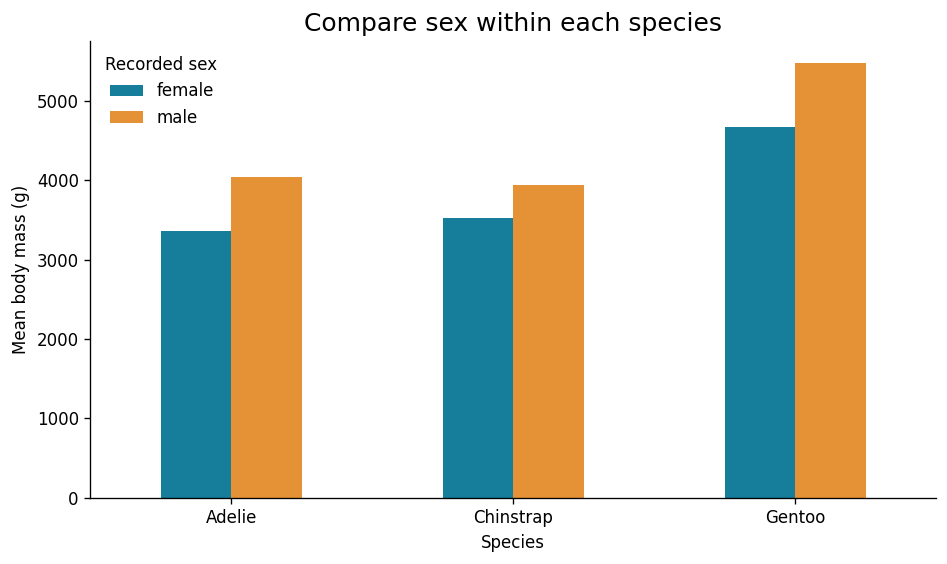

**Finding:** The pooled flipper–mass correlation is 0.871. Within species it ranges from 0.468 to 0.703. Group membership explains part of the pooled pattern.

In [5]:
sex_summary = sex_data.groupby(["species", "sex"]).body_mass_g.agg(["count", "mean", "median"])
display(sex_summary.round(1))
display(pd.crosstab(df.species, df.island))
sex_summary.to_csv(OUT / "mass_by_species_and_sex.csv")
pd.crosstab(df.species, df.island).to_csv(OUT / "species_island_counts.csv")
ax = sex_summary["mean"].unstack().plot.bar(figsize=(8, 4.8), color=COLORS[:2], rot=0)
ax.set(ylabel="Mean body mass (g)", xlabel="Species", title="Compare sex within each species")
ax.legend(title="Recorded sex", frameon=False)
savefig("mass_by_species_and_sex.png")
results = {"raw_rows": len(df), "morphology_rows": len(morph), "sex_analysis_rows": len(sex_data),
           "pooled_correlation": float(correlations.iloc[0].pearson_r),
           "correlations": correlations.to_dict(orient="records"),
           "species_summary": summary.reset_index().to_dict(orient="records")}
save_json("metrics.json", results)
takeaway = (f"The pooled flipper–mass correlation is {results['pooled_correlation']:.3f}. "
            f"Within species it ranges from {correlations.iloc[1:].pearson_r.min():.3f} to "
            f"{correlations.iloc[1:].pearson_r.max():.3f}. Group membership explains part of the pooled pattern.")
display(Markdown("**Finding:** " + takeaway))


## Conclusions and limits

Gentoo penguins have the largest mean mass in this sample. Mass and flipper length are positively associated both overall and within each species, but the pooled relationship is stronger. This is a practical reason to examine subgroups before interpreting a single correlation.

These observations do not show that longer flippers cause higher mass. The sample covers only three species in a particular place and period. Missing data and nonrandom sampling may affect estimates; the bootstrap does not fix those limitations.

**Next experiment:** compare the within-species relationship by year, reporting sample sizes, then investigate whether an island comparison is possible within the same species.

**Learning checks:** Why keep rows with missing sex for the scatterplot? Why is a bootstrap interval different from the spread of individual masses? Why can pooling groups strengthen correlation?

**Assistance:** This educational project was developed with ChatGPT/Codex assistance. The code and results were executed and checked.
